Ссылка на датасет: https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package?select=weatherAUS.csv

Этот набор данных содержит примерно 10 лет ежедневных метеорологических наблюдений с многочисленных австралийских метеостанций.
Переменная RainTomorrow является целевой переменной для прогнозирования. Она означает: шел ли дождь на следующий день, Да или Нет?
В этом столбце значение «Да» равно, если количество осадков за этот день составило 1 мм или более.

## **_Задания_**

In [1]:
import pandas as pd
import numpy as np
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [2]:
import os
print("Текущая директория:", os.getcwd())
print("Файлы в ней:", os.listdir())

Текущая директория: D:\Projects_in_Python\homework_1
Файлы в ней: ['ml-seminar-1.ipynb', 'rain_in_Australia_homework1.ipynb', 'Rain_in_Australia__KotegoV_n_a', 'weatherAUS.csv', 'weatherAUS.csv (1).zip']


## **_Загрузка данных_**

In [3]:
# путь к ZIP-файлу
zip_path = "weatherAUS.csv (1).zip"
# распаковка в текущую папку
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(".")

print("Распакованные файлы:", os.listdir())

Распакованные файлы: ['ml-seminar-1.ipynb', 'rain_in_Australia_homework1.ipynb', 'Rain_in_Australia__KotegoV_n_a', 'weatherAUS.csv', 'weatherAUS.csv (1).zip']


In [4]:
df = pd.read_csv("weatherAUS.csv")
df.sample(5)

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
41161,2013-09-09,Williamtown,17.1,26.5,0.0,NaN,NaN,NW,24.0,N,...,77.0,54.0,1021.5,1014.8,8.0,NaN,20.4,25.1,No,No
31315,2011-03-16,Sydney,19.3,28.3,0.0,3.2,7.7,ESE,33.0,W,...,77.0,65.0,1017.2,1016.8,NaN,NaN,22.3,25.3,No,Yes
144635,2015-03-24,Uluru,19.1,29.1,0.0,NaN,NaN,E,43.0,ESE,...,36.0,28.0,1018.9,1014.9,NaN,7.0,20.8,27.6,No,No
44226,2013-10-04,Wollongong,10.3,20.3,0.0,NaN,NaN,SW,41.0,SSW,...,44.0,42.0,1022.8,1019.3,NaN,NaN,15.3,16.8,No,No
1179,2012-03-24,Albury,8.9,19.7,0.4,NaN,NaN,WSW,37.0,W,...,79.0,54.0,1015.0,1015.4,7.0,5.0,11.1,17.5,No,No


In [5]:
# размерность
df.shape
# 145460 - строк, 23 - столбца

(145460, 23)

In [6]:
df.size
# общее количество ячеек

3345580

In [7]:
df.columns
# посмотрю, какие колонки существуют

Index(['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation',
       'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm',
       'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
       'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am',
       'Temp3pm', 'RainToday', 'RainTomorrow'],
      dtype='str')

## **EDA (Exploration data analysis)**

In [8]:
df.info()
# имеется строки и вещественные числа
# date - представлена в виде строки, а не в виде даты
# location - место
# mintemp - минимальная температура
# maxtemp - максимальная температура
# evarporation - испарение
# sun shine - солнечный свет
#  windGustDir фиксирует именно направление, откуда дует ветер в моменты резких порывов (когда его скорость резко возрастает)
# WindGustSpeed в прогнозах погоды — это максимальная скорость ветра, которую можно ожидать в моменты порывов
# WindDir9am - это обозначение направления ветра в 9 часов утра по местному времени
# WindDir3pm - это обозначение направления ветра в 15:00 (3 часа дня)
# WindSpeed9am - это показатель скорости ветра в 9 часов утра
# WindSpeed3pm - это параметр в прогнозе погоды, который обозначает скорость ветра в 15:00 (3 часа дня)
# Humidity9am  - в прогнозе погоды — это показатель относительной влажности воздуха, измеренный в 9 часов утра по местному времени
# Humidity3pm - в прогнозе погоды — это показатель относительной влажности воздуха, измеренный в 3 часа дня по местному времени
# Pressure9am в прогнозе погоды — это показатель атмосферного давления, измеренного в 9 часов утра
# Pressure3pm - в прогнозе погоды — это показатель атмосферного давления, измеренного в 3 часа дня
# Cloud (9 am) в контексте погоды — это показатель общего количества облаков в 9 часов утра по местному времени
# Cloud3pm  в контексте погоды — это показатель общего количества облаков в 3 часа дня по местному времени
# Temp9am - температура в 9 утра
# Temp3pm - температура в 3 часа дня
#  RainToday - дождь сегодня
# RainTomorrow - долждь завтра утром


<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null   float64


## **_Анализ числовых переменных_**

In [9]:
# посмотрим на числовые переменные
df.describe().round(2)
# 1. если смотреть на evaporation, sunshine, windgustspeend, humidity, pressure, cloud в рамках с 25 по 75 квантиля данные выглядит линейными
# 2. понадобится масштабирование, так как данные сильно отличаются по весу
# 3. по-первому впечатлению нет экстремальных выбросов

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,143975.00,144199.00,142199.00,82670.00,75625.00,135197.00,143693.00,142398.00,142806.00,140953.00,130395.00,130432.00,89572.00,86102.00,143693.00,141851.00
mean,12.19,23.22,2.36,5.47,7.61,40.04,14.04,18.66,68.88,51.54,1017.65,1015.26,4.45,4.51,16.99,21.68
std,6.40,7.12,8.48,4.19,3.79,13.61,8.92,8.81,19.03,20.80,7.11,7.04,2.89,2.72,6.49,6.94
min,-8.50,-4.80,0.00,0.00,0.00,6.00,0.00,0.00,0.00,0.00,980.50,977.10,0.00,0.00,-7.20,-5.40
25%,7.60,17.90,0.00,2.60,4.80,31.00,7.00,13.00,57.00,37.00,1012.90,1010.40,1.00,2.00,12.30,16.60
50%,12.00,22.60,0.00,4.80,8.40,39.00,13.00,19.00,70.00,52.00,1017.60,1015.20,5.00,5.00,16.70,21.10
75%,16.90,28.20,0.80,7.40,10.60,48.00,19.00,24.00,83.00,66.00,1022.40,1020.00,7.00,7.00,21.60,26.40
max,33.90,48.10,371.00,145.00,14.50,135.00,130.00,87.00,100.00,100.00,1041.00,1039.60,9.00,9.00,40.20,46.70


In [10]:
# посмотрим на пустые значения
df.isnull().sum()
# очень много пустых значений, которые либо нужно удалить, либо чем-то заполнить

Date                 0
Location             0
MinTemp           1485
MaxTemp           1261
Rainfall          3261
Evaporation      62790
Sunshine         69835
WindGustDir      10326
WindGustSpeed    10263
WindDir9am       10566
WindDir3pm        4228
WindSpeed9am      1767
WindSpeed3pm      3062
Humidity9am       2654
Humidity3pm       4507
Pressure9am      15065
Pressure3pm      15028
Cloud9am         55888
Cloud3pm         59358
Temp9am           1767
Temp3pm           3609
RainToday         3261
RainTomorrow      3267
dtype: int64

## **Анализ категориальных переменных**

Теперь взгляну детальнее на категориальные переменные.

In [11]:
df.describe(include='object')
#  популярных значениях есть No,видимо бинарный признак
# в основном самый популярный город - Канберра

,Date,Location,WindGustDir,WindDir9am,WindDir3pm,RainToday,RainTomorrow
count,145460,145460,135134,134894,141232,142199,142193
unique,3436,49,16,16,16,2,2
top,2013-03-01,Canberra,W,N,SE,No,No
freq,49,3436,9915,11758,10838,110319,110316


In [12]:
cat = [var for var in df.select_dtypes(include='object')]
print(f" Всего категориальных переменных: {len(cat)}")
print(f"Категориальные переменные : {cat}")

 Всего категориальных переменных: 7
Категориальные переменные : ['Date', 'Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']


In [13]:
df[cat].head()

,Date,Location,WindGustDir,WindDir9am,WindDir3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,W,W,WNW,No,No
1,2008-12-02,Albury,WNW,NNW,WSW,No,No
2,2008-12-03,Albury,WSW,W,WSW,No,No
3,2008-12-04,Albury,NE,SE,E,No,No
4,2008-12-05,Albury,W,ENE,NW,No,No


In [14]:
# посмотрим пустые значения в категориальных признаках
df[cat].isnull().sum()

Date                0
Location            0
WindGustDir     10326
WindDir9am      10566
WindDir3pm       4228
RainToday        3261
RainTomorrow     3267
dtype: int64

In [15]:
# уникальные значения в столбце
print(df['WindGustDir'].unique())
print(df['WindDir9am'].unique())
print(df['WindDir3pm'].unique())
print(df['RainToday'].unique())
print(df['RainTomorrow'].unique())
# пустые значения обозначены nan
# также raintoday, raintomorrow - бинарные признаки
# остальные признаки - категориальные c конечным множеством значений [windgustdir, winddir9am, wind3pm]

<StringArray>
[  'W', 'WNW', 'WSW',  'NE', 'NNW',   'N', 'NNE',  'SW',   nan, 'ENE', 'SSE',
   'S',  'NW',  'SE', 'ESE',   'E', 'SSW']
Length: 17, dtype: str
<StringArray>
[  'W', 'NNW',  'SE', 'ENE',  'SW', 'SSE',   'S',  'NE',   nan, 'SSW',   'N',
 'WSW', 'ESE',   'E',  'NW', 'WNW', 'NNE']
Length: 17, dtype: str
<StringArray>
['WNW', 'WSW',   'E',  'NW',   'W', 'SSE', 'ESE', 'ENE', 'NNW', 'SSW',  'SW',
  'SE',   'N',   'S', 'NNE',   nan,  'NE']
Length: 17, dtype: str
<StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str
<StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str


In [16]:
# проверю мощность множества в категориальных переменных
for var in cat:
    print(f"{var} содержит {len(df[var].unique())} меток")
# в дате много меток, с ней нужно работать отдельно

Date содержит 3436 меток
Location содержит 49 меток
WindGustDir содержит 17 меток
WindDir9am содержит 17 меток
WindDir3pm содержит 17 меток
RainToday содержит 3 меток
RainTomorrow содержит 3 меток


In [17]:
# дата содержит год, месяц и число
# превращаем строку в дату
df['Date'] = pd.to_datetime(df['Date'])
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['day'] = df['Date'].dt.day

In [18]:
# словарь для разделения даты на сезоны
# Поскольку Австралия находится в Южном полушарии, сезоны здесь противоположны привычным нам. Отсчёт идёт строго по датам:
#Лето — декабрь, январь, февраль.
#Осень — март, апрель, май.
#Зима — июнь, июль, август.
#Весна — сентябрь, октябрь, ноябрь.
season_map = {
    12: 'Summer', 1: 'Summer', 2: 'Summer',
    3: 'Autumn', 4: 'Autumn', 5: 'Autumn',
    6: 'Winter', 7: 'Winter', 8: 'Winter',
    9: 'Spring', 10: 'Spring', 11: 'Spring'
}

df['Season'] = df['Date'].dt.month.map(season_map)
df['Season'].value_counts()

Season
Autumn    38264
Winter    36737
Spring    35337
Summer    35122
Name: count, dtype: int64

In [19]:
df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,year,month,day,Season
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,8.0,NaN,16.9,21.8,No,No,2008,12,1,Summer
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,NaN,NaN,17.2,24.3,No,No,2008,12,2,Summer
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,NaN,2.0,21.0,23.2,No,No,2008,12,3,Summer
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,NaN,NaN,18.1,26.5,No,No,2008,12,4,Summer
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,7.0,8.0,17.8,29.7,No,No,2008,12,5,Summer


In [20]:
# удалю, так как разбила
df.drop(['Date'], axis=1, inplace=True)

In [21]:
df.head(5)

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,year,month,day,Season
0,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,...,8.0,NaN,16.9,21.8,No,No,2008,12,1,Summer
1,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,...,NaN,NaN,17.2,24.3,No,No,2008,12,2,Summer
2,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,...,NaN,2.0,21.0,23.2,No,No,2008,12,3,Summer
3,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,...,NaN,NaN,18.1,26.5,No,No,2008,12,4,Summer
4,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,...,7.0,8.0,17.8,29.7,No,No,2008,12,5,Summer


In [22]:
df['Location'].value_counts()

Location
Canberra            3436
Sydney              3344
Melbourne           3193
Brisbane            3193
Adelaide            3193
Perth               3193
Hobart              3193
Darwin              3193
Albury              3040
Wollongong          3040
MountGinini         3040
Ballarat            3040
Bendigo             3040
Cairns              3040
GoldCoast           3040
Townsville          3040
MountGambier        3040
Albany              3040
Launceston          3040
AliceSprings        3040
Newcastle           3039
Penrith             3039
Tuggeranong         3039
BadgerysCreek       3009
Cobar               3009
CoffsHarbour        3009
Moree               3009
NorfolkIsland       3009
Richmond            3009
SydneyAirport       3009
WaggaWagga          3009
Williamtown         3009
Sale                3009
MelbourneAirport    3009
Mildura             3009
Portland            3009
Watsonia            3009
Dartmoor            3009
Nuriootpa           3009
Woomera         

### **_Визуализация_**

### **1.Распределение классов, целевая переменная Y**

In [23]:
target_col = 'RainTomorrow'

In [24]:
# автоматически отфильтрую существующие столбцы
cat = [col for col in cat if col in df.columns]
df[cat].head()

,Location,WindGustDir,WindDir9am,WindDir3pm,RainToday,RainTomorrow
0,Albury,W,W,WNW,No,No
1,Albury,WNW,NNW,WSW,No,No
2,Albury,WSW,W,WSW,No,No
3,Albury,NE,SE,E,No,No
4,Albury,W,ENE,NW,No,No


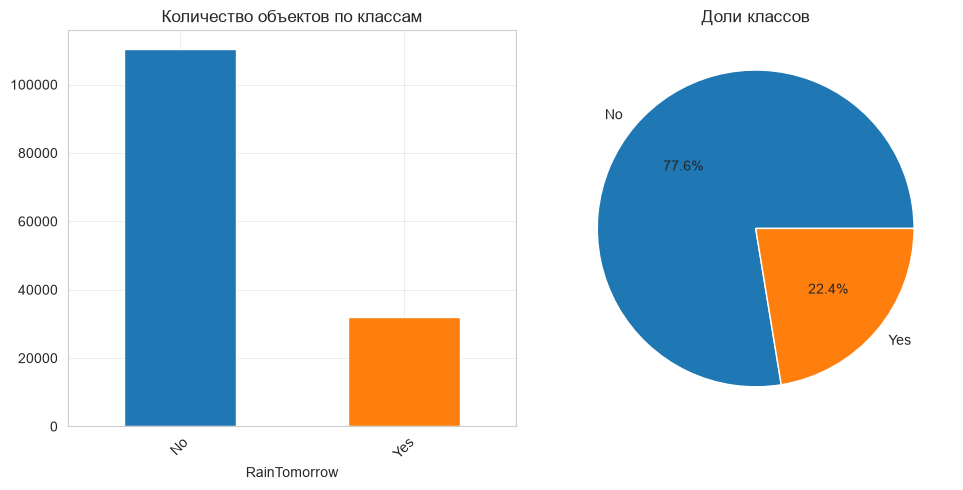

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

df[target_col].value_counts().plot.bar(ax=axes[0], color=sns.color_palette('tab10'))
axes[0].set_title('Количество объектов по классам')
axes[0].tick_params(axis='x', rotation=45)

df[target_col].value_counts(normalize=True).plot.pie(ax=axes[1], autopct='%1.1f%%', colors=sns.color_palette('tab10'))
axes[1].set_ylabel('')
axes[1].set_title('Доли классов')
plt.tight_layout()
plt.show()
# можно увидеть очень сильный дисбаланс классов

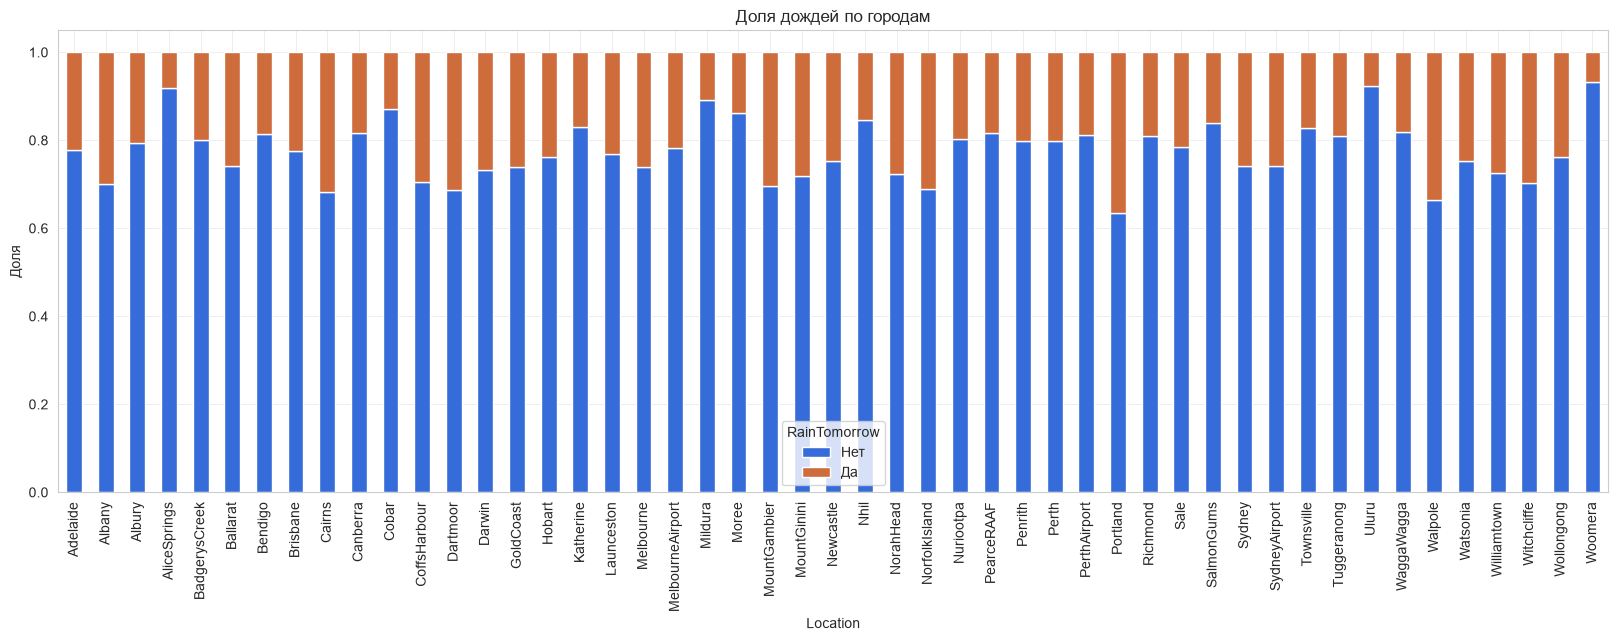

In [26]:
pd.crosstab(df['Location'], df[target_col], normalize='index').plot(kind='bar', stacked=True, figsize=(20, 6))
plt.legend(title='RainTomorrow', labels=['Нет', 'Да'])
plt.title('Доля дождей по городам')
plt.ylabel('Доля')
plt.show()
# удя по всему дожди  - не частое явление в Австралии

### **2.Распределение признаков**

In [27]:
# числовые переменные
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

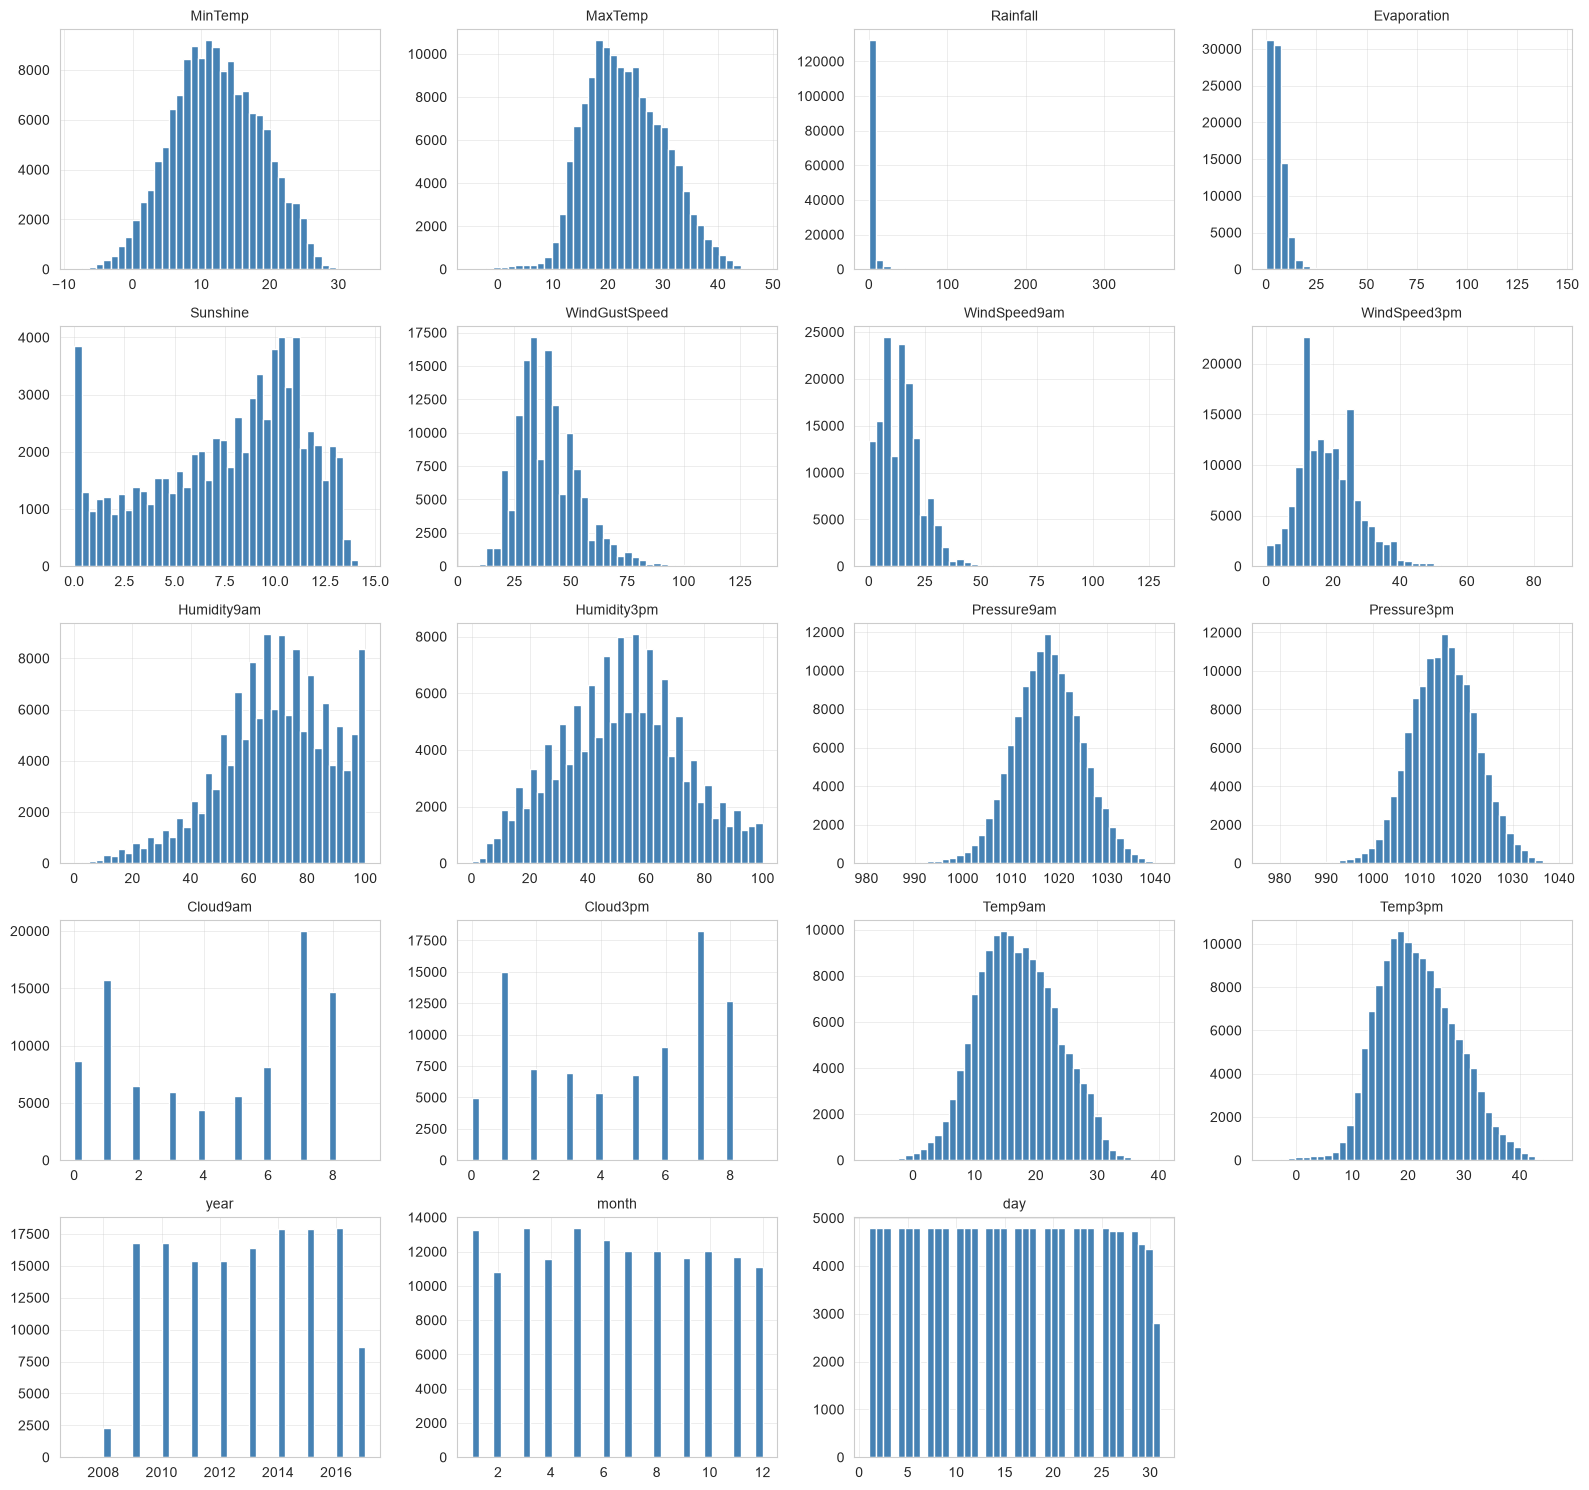

In [28]:
n_cols = len(numeric_cols)
n_rows = (n_cols + 3) // 4
fig, axes = plt.subplots(n_rows, 4, figsize=(16, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    df[col].hist(bins=40, ax=axes[i], color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=10)

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

**Корреляционная матрица**

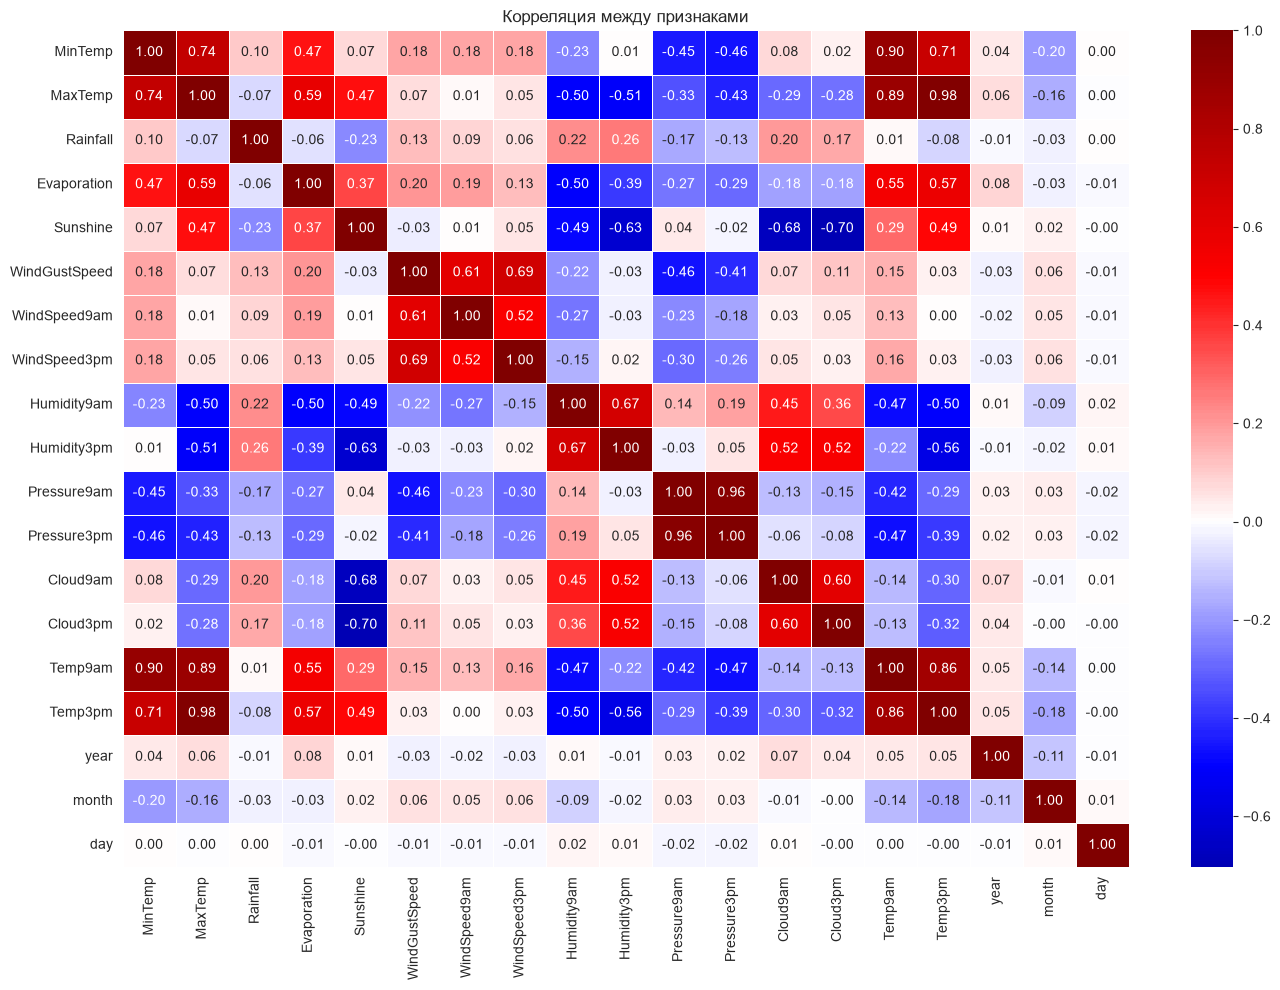

In [29]:
plt.figure(figsize=(14, 10))
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='seismic', center=0, linewidths=0.5)
plt.title('Корреляция между признаками')
plt.tight_layout()
plt.show()

### **Boxplot для коррелирующих признаков**

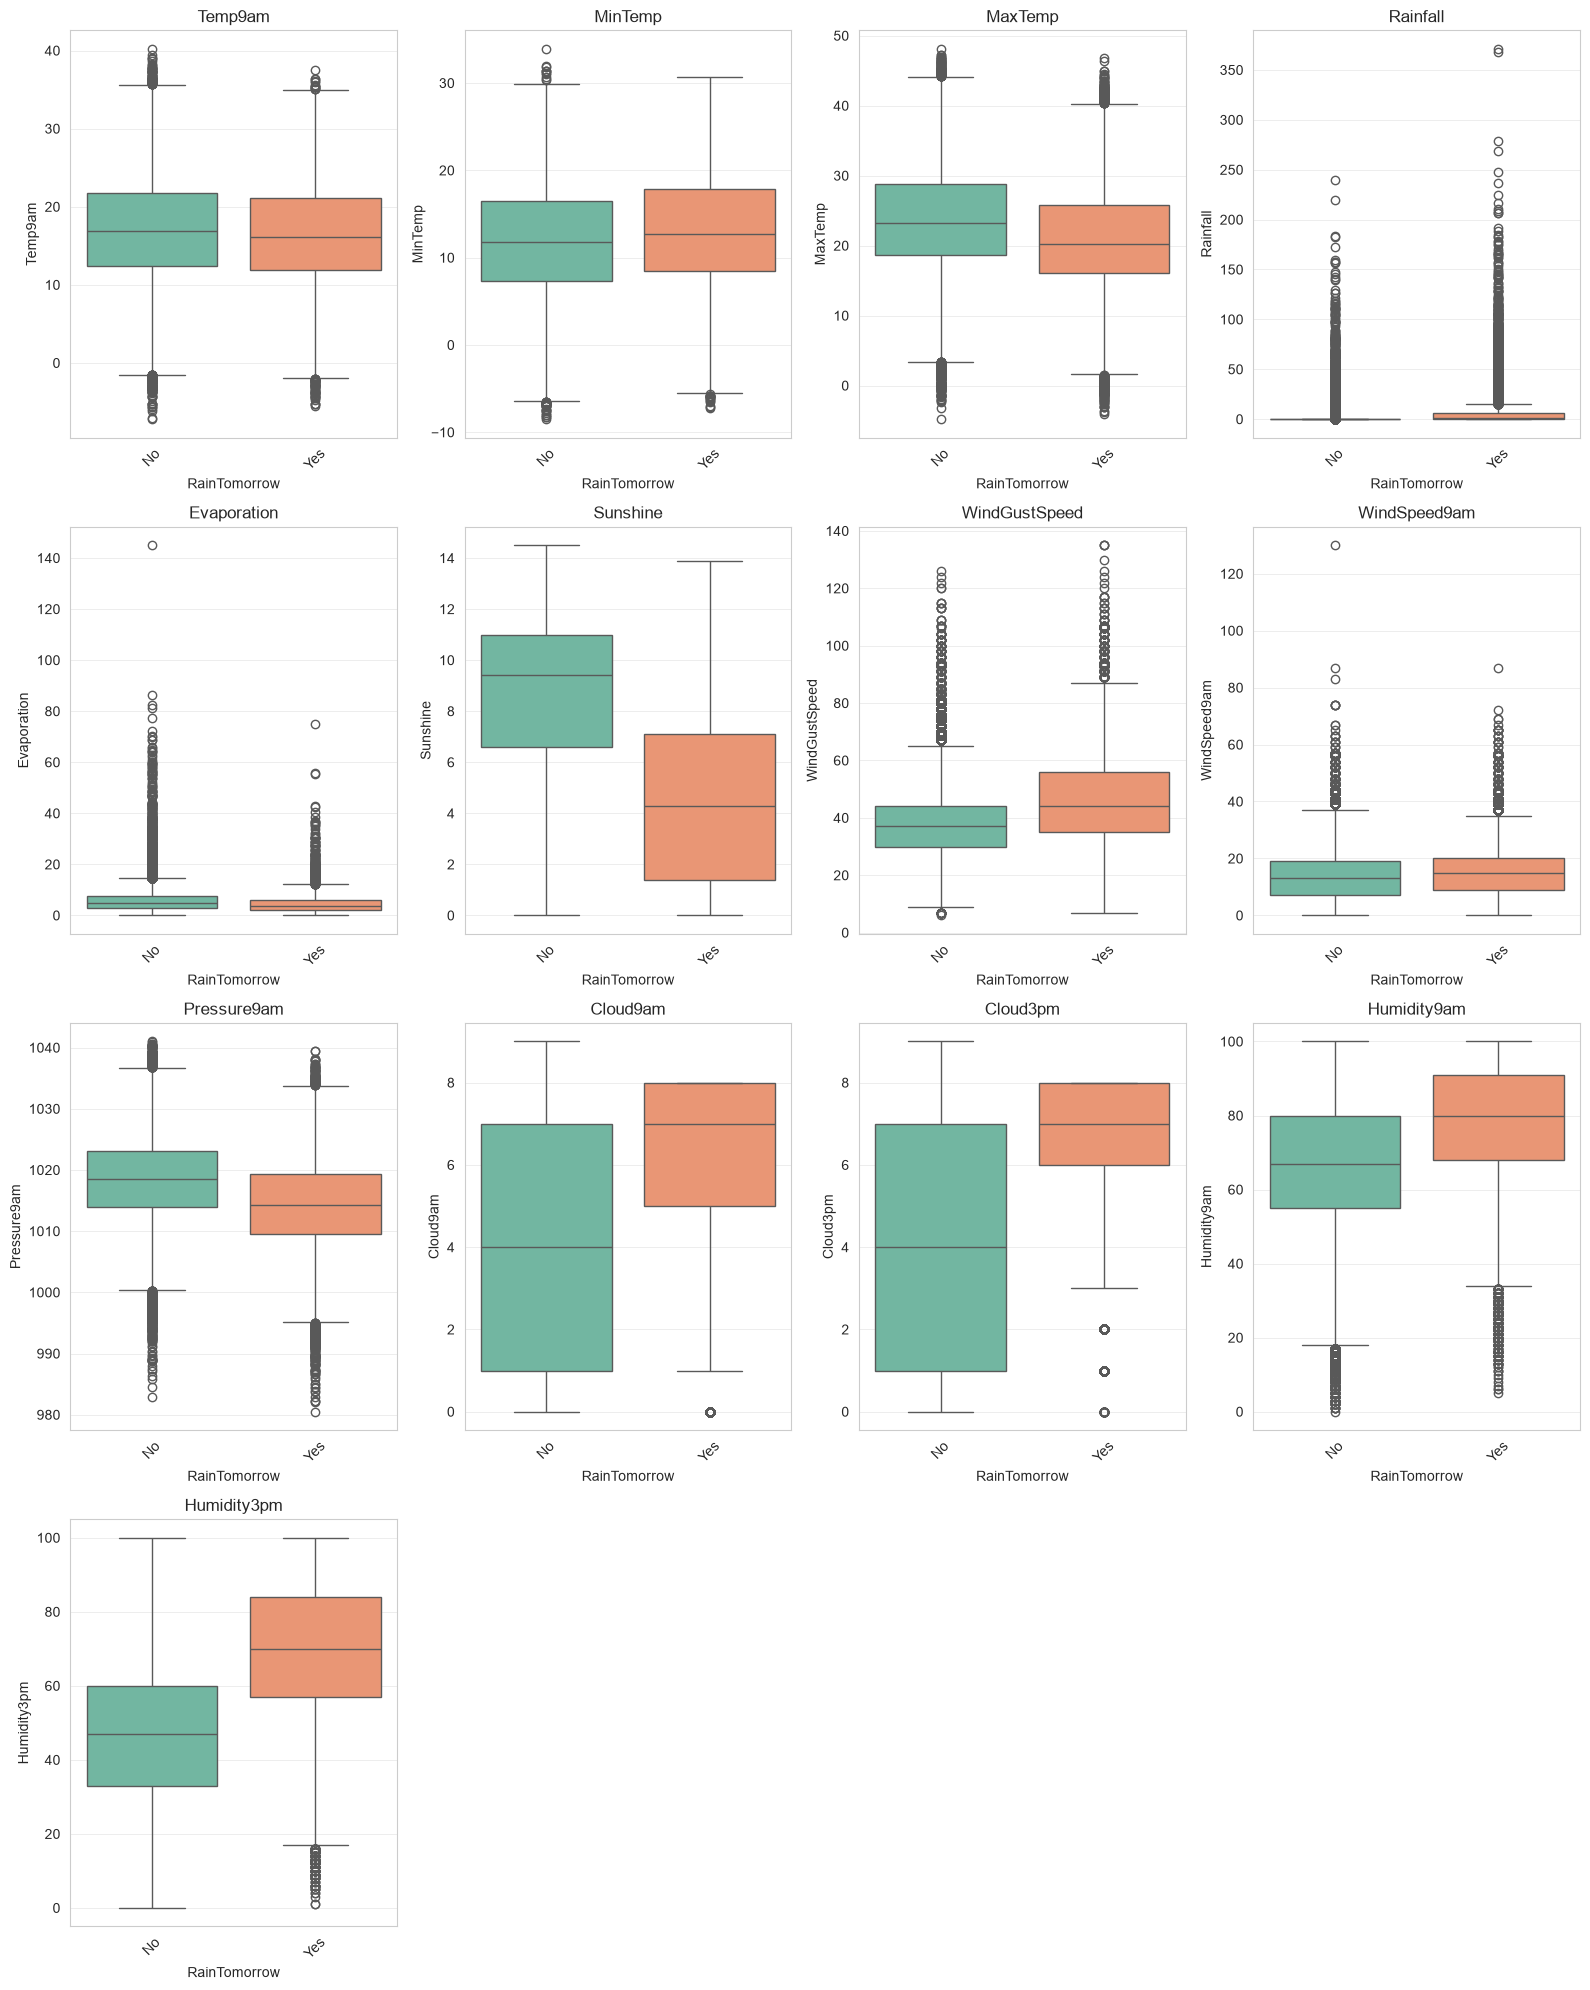

In [30]:
import math
top_features = ['Temp9am', 'Temp3am', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation',
                'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3am',
                'Pressure9am', 'Pressure3am', 'Cloud9am', 'Cloud3pm', 'Humidity9am', 'Humidity3pm']

existing_features = [col for col in top_features if col in df.columns]
n_cols = 4
n_rows = math.ceil(len(existing_features) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
axes = axes.flatten()

for idx, col in enumerate(existing_features):
    sns.boxplot(data=df, x=target_col, y=col, ax=axes[idx], palette='Set2')
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].set_title(col)
for idx in range(len(existing_features), len(axes)):
    axes[idx].axis('off')
plt.tight_layout()
plt.show()

In [162]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, log_loss,
                             roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, log_loss,
                             roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             ConfusionMatrixDisplay)
from sklearn.impute import SimpleImputer
from sklearn.utils import resample


### **Обработка пустых значений**

In [163]:
# категориальные признаки, которые не содержат 0
cat1 = [var for var in cat if df[var].isnull().sum()!=0]
print(df[cat1].isnull().sum())

WindGustDir     10326
WindDir9am      10566
WindDir3pm       4228
RainToday        3261
RainTomorrow     3267
dtype: int64


In [164]:
df['RainToday'].unique()

<StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str

In [165]:
df['RainTomorrow'].unique()

<StringArray>
['No', 'Yes', nan]
Length: 3, dtype: str

In [166]:
df_part_1 = df.copy()

In [167]:
df_part_1.head(5)

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,year,month,day,Season
0,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,...,8.0,NaN,16.9,21.8,No,No,2008,12,1,Summer
1,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,...,NaN,NaN,17.2,24.3,No,No,2008,12,2,Summer
2,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,...,NaN,2.0,21.0,23.2,No,No,2008,12,3,Summer
3,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,...,NaN,NaN,18.1,26.5,No,No,2008,12,4,Summer
4,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,...,7.0,8.0,17.8,29.7,No,No,2008,12,5,Summer


In [168]:
# это бинарные признаки, преобразуем их в число
# заполню модой, самым популярным значением
df_part_1['RainToday']=df_part_1['RainToday'].fillna(df_part_1['RainToday'].mode()[0])
# это бинарные признаки, преобразуем их в число
df_part_1['RainToday'] = df_part_1['RainToday'].map({'Yes': 1, 'No': 0})
#df_part_1['RainTomorrow'] = df_part_1['RainTomorrow'].map({'Yes': 1, 'No': 0})

In [169]:
# тоже самое сделаю с rain tomorrow, это бинарный признак
df_part_1['RainTomorrow']=df_part_1['RainTomorrow'].fillna(df_part_1['RainTomorrow'].mode()[0])
df_part_1['RainTomorrow'] = df_part_1['RainTomorrow'].map({'Yes': 1, 'No': 0})

In [170]:
# заполню категориальных признаки все, кроме rain tomorrow  модой
df_part_1['Location'] = df_part_1['Location'].fillna(df_part_1['Location'].mode()[0])
df_part_1['WindGustDir'] = df_part_1['WindGustDir'].fillna(df_part_1['WindGustDir'].mode()[0])
df_part_1['WindDir9am'] = df_part_1['WindDir9am'].fillna(df_part_1['WindDir9am'].mode()[0])
df_part_1['WindDir3pm'] = df_part_1['WindDir3pm'].fillna(df_part_1['WindDir3pm'].mode()[0])

## **Обучение_1**

In [171]:
import random
random.seed(150)

In [172]:
# Разделение выборки
X = df_part_1.drop(columns=['RainTomorrow'])
y = df_part_1['RainTomorrow']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=150, stratify=y)

In [173]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
numeric_features = df_part_1.select_dtypes(include=['int64', 'float64', 'int32']).columns.tolist()
numeric_features = [col for col in numeric_features if col != 'RainTomorrow']
categorical_features = df_part_1.select_dtypes(include=['object']).columns.tolist()

print(f"Числовые признаки: {numeric_features[:]}...")
print(f"Категориальные признаки: {categorical_features}")
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # Заполняю пропуски медианой
    ('scaler', StandardScaler())]) # масштабирую числовые признаки
categorical_transformer = Pipeline(steps=[('onehot', OneHotEncoder(drop='first', sparse_output=False))])

Числовые признаки: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'year', 'month', 'day']...
Категориальные признаки: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'Season']


In [178]:
# Объединяю в ColumnTransformer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough'
)
# полный пайплайн
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(penalty='l2', C=0.1, random_state=150, class_weight='balanced', solver='liblinear'))
])

In [179]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, log_loss,
                             roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             ConfusionMatrixDisplay)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

f1_score(y_test, y_pred)

0.6129500031523863

In [180]:
metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC', 'Log-Loss'],
    'Value': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_proba),
        log_loss(y_test, y_proba)
    ]
}).round(4)

In [181]:
metrics_df

,Metric,Value
0,Accuracy,0.7890
1,Precision,0.5124
2,Recall,0.7625
3,F1 Score,0.6130
4,ROC-AUC,0.8645
5,Log-Loss,0.4582


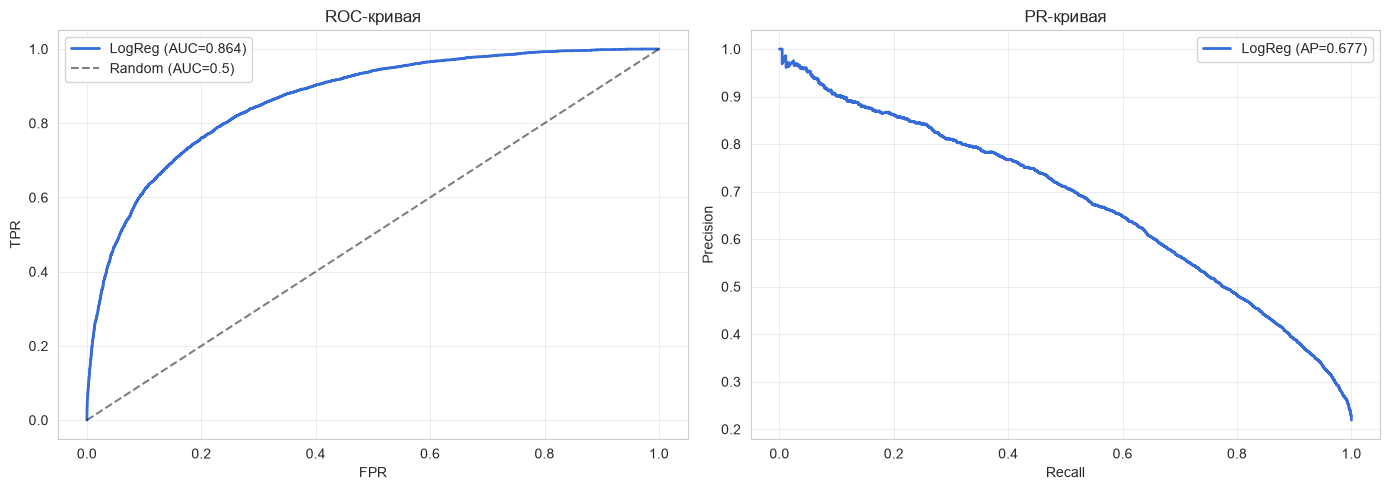

In [182]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[0].plot(fpr, tpr, linewidth=2, label=f'LogReg (AUC={roc_auc_score(y_test, y_proba):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (AUC=0.5)')
axes[0].set_xlabel('FPR')
axes[0].set_ylabel('TPR')
axes[0].set_title('ROC-кривая')
axes[0].legend()

prec, rec, _ = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)
axes[1].plot(rec, prec, linewidth=2, label=f'LogReg (AP={ap:.3f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('PR-кривая')
axes[1].legend()

plt.tight_layout()
plt.show()

## **Обучение_2**

Проблема этого датасета в выбросах и несбалансированных классах, поэтому воспользуюсь ансемплингом и доведу миноритарный класс до размера мажоритарного, затем объединю их и проверю баланс.

In [40]:
# отделяю класс Нет дождя (мажоритарный)
majority_class_data = df_part_1[df_part_1['RainTomorrow'] == 0]
# отделяю класс Дождь (миноритарный)
minority_class_data = df_part_1[df_part_1['RainTomorrow'] == 1]

# Апсемплинг миноритарного класса
upsampled_minority_class = resample(
    minority_class_data,
    replace=True,              # с повторениями
    n_samples=len(majority_class_data),  # довожу до размера мажоритарного
    random_state=150           # для воспроизводимости
)
# объединение обоих классов
df_part_1_balanced = pd.concat([majority_class_data, upsampled_minority_class], axis=0)
df_part_1_balanced = df_part_1_balanced.sample(frac=1, random_state=42).reset_index(drop=True)
print("Распределение классов после апсемплинга:")
print(df_part_1_balanced['RainTomorrow'].value_counts())
print(f"\nРазмер датасета: {df_part_1_balanced.shape}")


Распределение классов после апсемплинга:
RainTomorrow
1    113583
0    113583
Name: count, dtype: int64

Размер датасета: (227166, 26)


In [41]:
df_part_1_balanced.sample(5)

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,year,month,day,Season
64049,CoffsHarbour,13.3,21.0,0.4,NaN,NaN,ENE,33.0,NW,NE,...,NaN,7.0,18.2,18.5,0,1,2015,9,5,Spring
157488,Woomera,18.7,37.2,0.0,15.6,9.5,N,39.0,N,N,...,1.0,5.0,25.0,35.2,0,0,2015,10,4,Spring
225523,MelbourneAirport,5.5,18.7,0.2,4.6,8.7,WNW,48.0,WNW,WNW,...,2.0,7.0,13.5,16.5,0,1,2016,11,1,Spring
177634,Townsville,24.2,29.1,21.4,8.6,1.0,NNW,41.0,SE,NW,...,8.0,7.0,26.3,27.7,1,1,2009,1,23,Summer
8263,Sale,15.5,23.2,2.2,NaN,NaN,E,30.0,N,E,...,7.0,6.0,16.9,22.0,1,0,2014,12,2,Summer


In [42]:
import random
random.seed(150)

In [43]:
# разделение выборки
X = df_part_1_balanced.drop(columns=['RainTomorrow'])
y = df_part_1_balanced['RainTomorrow']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=150, stratify=y)

In [44]:
#  разделение колоки
numeric_features = df_part_1_balanced.select_dtypes(include=['int64', 'float64', 'int32']).columns.tolist()
numeric_features = [col for col in numeric_features if col != 'RainTomorrow']
categorical_features = df_part_1_balanced.select_dtypes(include=['object', 'str']).columns.tolist()
print(f"Числовые признаки: {numeric_features[:]}...")
print(f"Категориальные признаки: {categorical_features}")

Числовые признаки: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'year', 'month', 'day']...
Категориальные признаки: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'Season']


In [45]:

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # остальное заполняется медианой
    ('scaler', StandardScaler())])
categorical_transformer = Pipeline(steps=[('onehot', OneHotEncoder(drop='first', sparse_output=False))])

In [46]:
#  ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough'
)
# полный пайплайн
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(penalty='l1', C=0.1, max_iter=1000, random_state=150, class_weight='balanced', solver='liblinear'))
])

**1. Бинарная классификация**

In [47]:
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

f1_score(y_test, y_pred)

0.7798369492582528

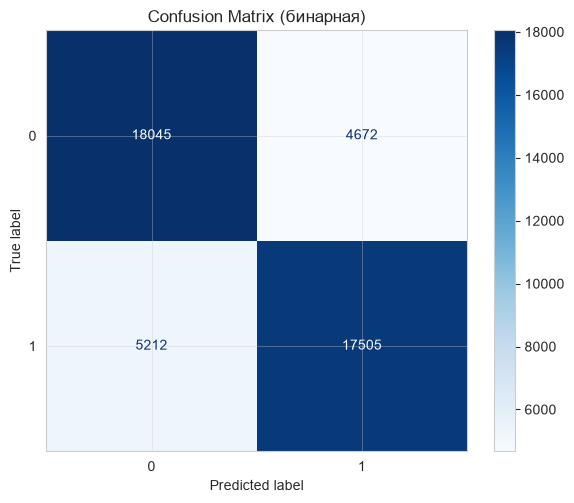

In [48]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap='Blues')
ax.set_title('Confusion Matrix (бинарная)')
plt.tight_layout()
plt.show()

In [49]:
metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC', 'Log-Loss'],
    'Value': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_proba),
        log_loss(y_test, y_proba)
    ]
}).round(4)

In [50]:
metrics_df

,Metric,Value
0,Accuracy,0.7825
1,Precision,0.7893
2,Recall,0.7706
3,F1 Score,0.7798
4,ROC-AUC,0.8660
5,Log-Loss,0.4574


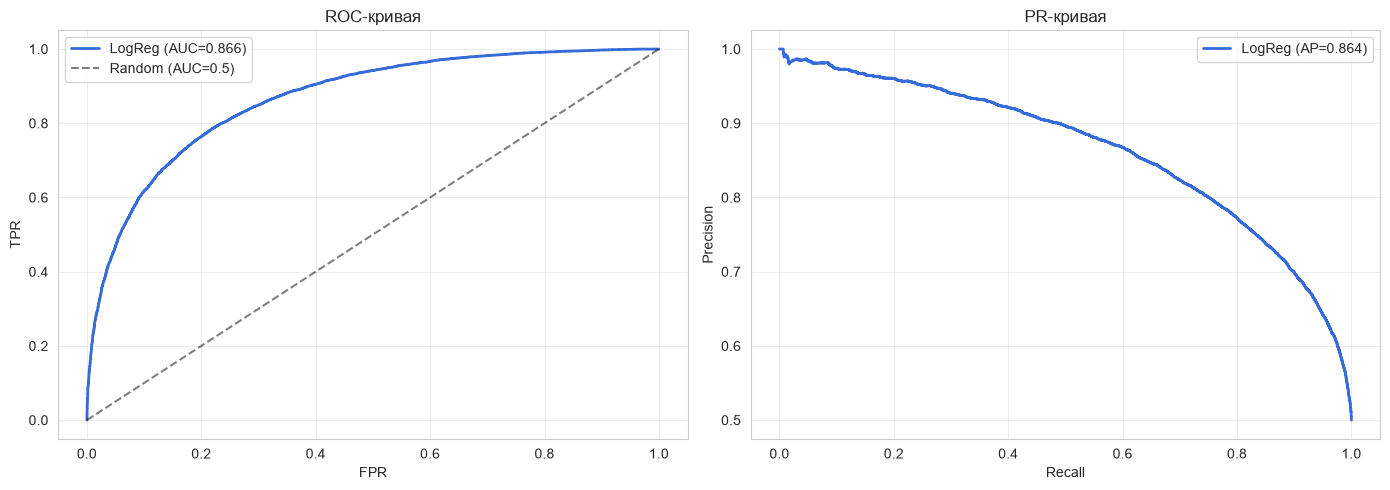

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[0].plot(fpr, tpr, linewidth=2, label=f'LogReg (AUC={roc_auc_score(y_test, y_proba):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (AUC=0.5)')
axes[0].set_xlabel('FPR')
axes[0].set_ylabel('TPR')
axes[0].set_title('ROC-кривая')
axes[0].legend()

prec, rec, _ = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)
axes[1].plot(rec, prec, linewidth=2, label=f'LogReg (AP={ap:.3f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('PR-кривая')
axes[1].legend()

plt.tight_layout()
plt.show()

In [52]:
coefs = pipeline.named_steps['classifier'].coef_[0]
# получаю имена признаков
numeric_feature_names = numeric_features
cat_encoder = pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
cat_feature_names = cat_encoder.get_feature_names_out(categorical_features)
feature_names = numeric_feature_names + list(cat_feature_names)

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefs,
    'Abs_Coefficient': np.abs(coefs)
}).sort_values('Abs_Coefficient', ascending=False)

In [53]:
coef_df

,Feature,Coefficient,Abs_Coefficient
11,Pressure3pm,-1.344242,1.344242
35,Location_Katherine,-1.287249,1.287249
9,Humidity3pm,1.229620,1.229620
42,Location_MountGinini,-1.023397,1.023397
58,Location_Townsville,-0.997648,0.997648
...,...,...,...
82,WindGustDir_WSW,0.000000,0.000000
56,Location_Sydney,0.000000,0.000000
68,WindGustDir_ENE,0.000000,0.000000
59,Location_Tuggeranong,0.000000,0.000000


Abs_Coefficient - это модуль числа. Он показывает силу влияния, безотносительно знака.


**Гипотеза 1:** Атмосферное давление является одним из самых важных признаков для прогнозирования дождя.

**Обоснование:** Падение давления - это классический предвестник циклона и осадков. Признаки Pressure3pm и Pressure9am будут важны, но , возможно, утреннее давление может быть лучшим индикатором для прогноза на следующий день.

**Вывод:** Гипотеза частично подтвердилась. Давление действительно важно, получается, что чем выше давление, тем меньше шансов на дождь, однако изменение давления в течение дня важнее, чем абсолютное значение утром. Давление в 3 часа дня оказалось важнее, чем давление в 9 утра.


**Гипотеза 2:** Категориальный признак «локация» (Location) окажется в числе самых сильных предикторов дождя.

**Вывод:** В топ-5 коэффициентов вошли три локации (Katherine, MountGinini, Townsville), гипотеза подтвердилась.



In [69]:
from sklearn.decomposition import PCA

In [70]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

In [130]:
random.seed(42)

In [131]:
X = df_part_1_balanced.drop(columns=['RainTomorrow'])
y = df_part_1_balanced['RainTomorrow']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
numeric_features = df_part_1_balanced.select_dtypes(include=['int64', 'float64', 'int32']).columns.tolist()
numeric_features = [col for col in numeric_features if col != 'RainTomorrow']
categorical_features = df_part_1_balanced.select_dtypes(include=['object', 'str']).columns.tolist()

In [132]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  # остальное заполняется медианой
    ('scaler', StandardScaler())])
categorical_transformer = Pipeline(steps=[('onehot', OneHotEncoder(drop='first', sparse_output=False))])
#  ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough'
)


In [133]:
# напишу функцию для оценки модели и обучения
def train_and_evaluate_model(pipeline, model_name, params_description="", use_pca=False):
    pipeline.fit(X_train, y_train)
    # Предсказания
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    # Метрики
    metrics = {
        'Model': model_name,
        'Params': params_description,
        'PCA': 'Yes' if use_pca else 'No',
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'Log-Loss': log_loss(y_test, y_proba)
    }

    return metrics, y_pred, y_proba

In [134]:
# Трансформирую данные через препроцессор
X_transformed = preprocessor.fit_transform(X_train)
# использую PCA
pca_full = PCA(random_state=42)
X_pca_full = pca_full.fit_transform(X_transformed)

In [135]:
explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# количество компонент для 95% дисперсии
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
n_components_90 = np.argmax(cumulative_variance >= 0.90) + 1
print(f"Компонент для 90% дисперсии: {n_components_90}")
print(f"Компонент для 95% дисперсии: {n_components_95}")
print(f"Всего признаков после OneHot: {X_transformed.shape[1]}")

Компонент для 90% дисперсии: 33
Компонент для 95% дисперсии: 55
Всего признаков после OneHot: 116


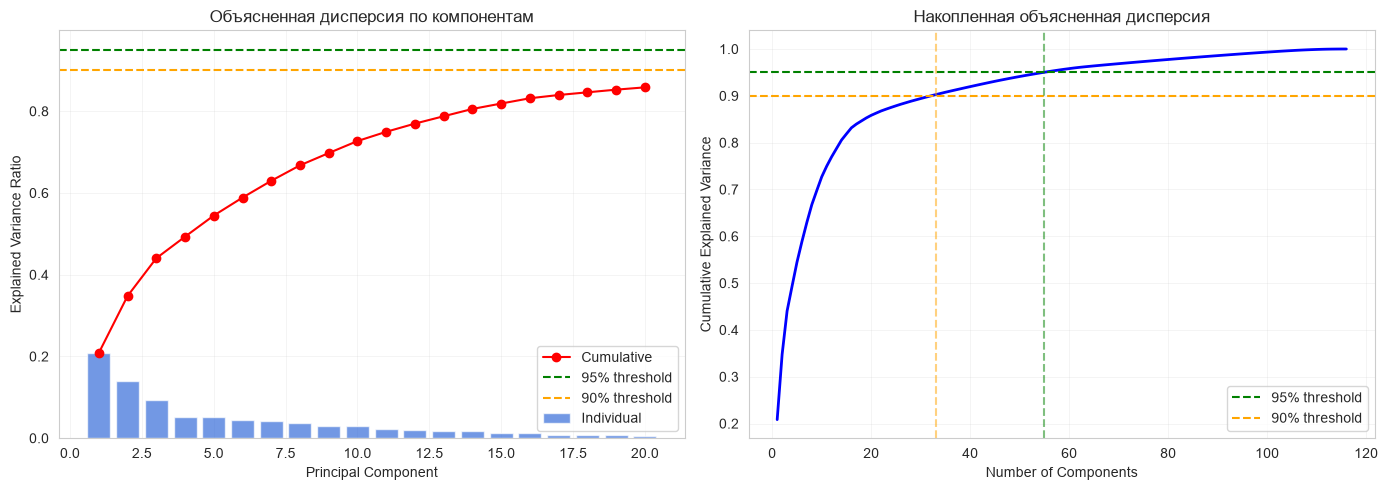

In [136]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Объясненная дисперсия
ax = axes[0]
ax.bar(range(1, 21), explained_variance[:20], alpha=0.7, label='Individual')
ax.plot(range(1, 21), cumulative_variance[:20], 'r-o', label='Cumulative')
ax.axhline(y=0.95, color='green', linestyle='--', label='95% threshold')
ax.axhline(y=0.90, color='orange', linestyle='--', label='90% threshold')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance Ratio')
ax.set_title('Объясненная дисперсия по компонентам')
ax.legend()
ax.grid(alpha=0.3)

# Накопленная дисперсия
ax = axes[1]
ax.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, 'b-', linewidth=2)
ax.axhline(y=0.95, color='green', linestyle='--', label='95% threshold')
ax.axhline(y=0.90, color='orange', linestyle='--', label='90% threshold')
ax.axvline(x=n_components_95, color='green', linestyle='--', alpha=0.5)
ax.axvline(x=n_components_90, color='orange', linestyle='--', alpha=0.5)
ax.set_xlabel('Number of Components')
ax.set_ylabel('Cumulative Explained Variance')
ax.set_title('Накопленная объясненная дисперсия')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [137]:
# количество компонент для PCA
PCA_COMPONENTS = n_components_95
print(f"Используем {PCA_COMPONENTS} компонент для PCA")

Используем 55 компонент для PCA


In [138]:
#списки и словари для хранения результатов
results_no_pca = []
models_no_pca = {}

In [139]:
# Логистическая регрессия
logreg_configs = [
    {'C': 0.01, 'penalty': 'l2', 'solver': 'liblinear', 'class_weight': 'balanced', 'name': 'LogReg_l2'},
    {'C': 0.1, 'penalty': 'l1', 'solver': 'liblinear', 'class_weight': 'balanced', 'name': 'LogReg_l1'},
    {'C': 1.0, 'penalty': 'l1', 'solver': 'liblinear', 'class_weight': 'balanced', 'name': 'LogReg_l1_part2'},
]

# Дерево решений
tree_configs = [
    {'max_depth': 3, 'min_samples_split': 5, 'min_samples_leaf': 20, 'class_weight': 'balanced', 'name': 'Tree_depth3'},
    {'max_depth': 5, 'min_samples_split': 7, 'min_samples_leaf': 50, 'class_weight': 'balanced', 'name': 'Tree_depth5'},
    {'max_depth': 7, 'min_samples_split': 10, 'min_samples_leaf': 100, 'class_weight': 'balanced', 'name': 'Tree_depth7'},
    {'max_depth': 10, 'min_samples_split': 20, 'min_samples_leaf': 120, 'class_weight': 'balanced', 'name': 'Tree_depth10'},
]

ОБУЧЕНИЕ модели без PCA

In [140]:
# Логистическая регрессия без PCA
print("\n--- Logistic Regression (без PCA) ---")
for config in logreg_configs:
    model_name = config['name']
    params_desc = f"C={config.get('C', 'N/A')}, {config.get('penalty', 'N/A')}"

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=42,
            **{k: v for k, v in config.items() if k != 'name'}
        ))
    ])

    metrics, y_pred, y_proba = train_and_evaluate_model(pipeline, model_name, params_desc, use_pca=False)
    results_no_pca.append(metrics)
    models_no_pca[model_name] = {'pipeline': pipeline, 'y_pred': y_pred, 'y_proba': y_proba}
    print(f"  {model_name}: F1={metrics['F1']:.4f}, ROC-AUC={metrics['ROC-AUC']:.4f}")


--- Logistic Regression (без PCA) ---
  LogReg_l2: F1=0.7793, ROC-AUC=0.8668
  LogReg_l1: F1=0.7790, ROC-AUC=0.8672
  LogReg_l1_part2: F1=0.7793, ROC-AUC=0.8674


In [141]:
# Дерево решений без PCA
print("\n--- Decision Tree (без PCA) ---")
for config in tree_configs:
    model_name = config['name']
    params_desc = f"max_depth={config['max_depth']}"

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(criterion='gini',
            random_state=42,
            **{k: v for k, v in config.items() if k != 'name'}
        ))
    ])

    metrics, y_pred, y_proba = train_and_evaluate_model(pipeline, model_name, params_desc, use_pca=False)
    results_no_pca.append(metrics)
    models_no_pca[model_name] = {'pipeline': pipeline, 'y_pred': y_pred, 'y_proba': y_proba}
    print(f"  {model_name}: F1={metrics['F1']:.4f}, ROC-AUC={metrics['ROC-AUC']:.4f}")


--- Decision Tree (без PCA) ---
  Tree_depth3: F1=0.7246, ROC-AUC=0.8022
  Tree_depth5: F1=0.7491, ROC-AUC=0.8333
  Tree_depth7: F1=0.7634, ROC-AUC=0.8506
  Tree_depth10: F1=0.7764, ROC-AUC=0.8633


ОБУЧЕНИЕ моделей с PCA

In [142]:
results_with_pca = []
models_with_pca = {}

# Логистическая регрессия с PCA
print("\nLogistic Regression (с PCA)")
for config in logreg_configs:
    model_name = f"{config['name']}_PCA"
    params_desc = f"C={config.get('C', 'N/A')}, {config.get('penalty', 'N/A')}"

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('pca', PCA(n_components=PCA_COMPONENTS, random_state=42)),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=42,
            **{k: v for k, v in config.items() if k != 'name'}
        ))
    ])

    metrics, y_pred, y_proba = train_and_evaluate_model(pipeline, model_name, params_desc, use_pca=True)
    results_with_pca.append(metrics)
    models_with_pca[model_name] = {'pipeline': pipeline, 'y_pred': y_pred, 'y_proba': y_proba}
    print(f"  {model_name}: F1={metrics['F1']:.4f}, ROC-AUC={metrics['ROC-AUC']:.4f}")


Logistic Regression (с PCA)
  LogReg_l2_PCA: F1=0.7705, ROC-AUC=0.8591
  LogReg_l1_PCA: F1=0.7708, ROC-AUC=0.8591
  LogReg_l1_part2_PCA: F1=0.7709, ROC-AUC=0.8591


In [143]:
# Дерево решений с PCA
print("\nDecision Tree (с PCA)")
for config in tree_configs:
    model_name = f"{config['name']}_PCA"
    params_desc = f"max_depth={config['max_depth']}"

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('pca', PCA(n_components=PCA_COMPONENTS, random_state=42)),
        ('classifier', DecisionTreeClassifier(criterion='gini',
            random_state=42,
            **{k: v for k, v in config.items() if k != 'name'}
        ))
    ])

    metrics, y_pred, y_proba = train_and_evaluate_model(pipeline, model_name, params_desc, use_pca=True)
    results_with_pca.append(metrics)
    models_with_pca[model_name] = {'pipeline': pipeline, 'y_pred': y_pred, 'y_proba': y_proba}
    print(f"  {model_name}: F1={metrics['F1']:.4f}, ROC-AUC={metrics['ROC-AUC']:.4f}")


Decision Tree (с PCA)
  Tree_depth3_PCA: F1=0.7284, ROC-AUC=0.8055
  Tree_depth5_PCA: F1=0.7464, ROC-AUC=0.8283
  Tree_depth7_PCA: F1=0.7628, ROC-AUC=0.8424
  Tree_depth10_PCA: F1=0.7776, ROC-AUC=0.8569


In [144]:
# Объединяю
all_results = results_no_pca + results_with_pca
results_df = pd.DataFrame(all_results)
results_df = results_df.round(4)

In [145]:
# Сортирую по F1
results_df_sorted = results_df.sort_values('F1', ascending=False)

In [146]:
results_df_sorted

,Model,Params,PCA,Accuracy,Precision,Recall,F1,ROC-AUC,Log-Loss
0,LogReg_l2,"C=0.01, l2",No,0.7826,0.7912,0.7678,0.7793,0.8668,0.4550
2,LogReg_l1_part2,"C=1.0, l1",No,0.7827,0.7915,0.7675,0.7793,0.8674,0.4541
1,LogReg_l1,"C=0.1, l1",No,0.7823,0.7911,0.7672,0.7790,0.8672,0.4544
13,Tree_depth10_PCA,max_depth=10,Yes,0.7753,0.7698,0.7855,0.7776,0.8569,0.4719
6,Tree_depth10,max_depth=10,No,0.7772,0.7792,0.7736,0.7764,0.8633,0.4615
9,LogReg_l1_part2_PCA,"C=1.0, l1",Yes,0.7742,0.7823,0.7597,0.7709,0.8591,0.4663
8,LogReg_l1_PCA,"C=0.1, l1",Yes,0.7741,0.7822,0.7597,0.7708,0.8591,0.4663
7,LogReg_l2_PCA,"C=0.01, l2",Yes,0.7738,0.7819,0.7594,0.7705,0.8591,0.4663
5,Tree_depth7,max_depth=7,No,0.7651,0.7689,0.7581,0.7634,0.8506,0.4778
12,Tree_depth7_PCA,max_depth=7,Yes,0.7630,0.7633,0.7624,0.7628,0.8424,0.4906


**Гипотеза 3:** Логистическая регрессия с регуляризацией (L1 и L2) покажет лучшее качество F1, чем деревья решений, так как признаки, скорее всего, имеют линейные зависимости с целевой переменной.
**Вывод:** Логистическая регрессия достигла F1 = 0.7793, деревья (глубина 7) — F1 0.7736, гипотеза подтвердилась.

**Гипотеза 4:** Применение PCA с сохранением 95% дисперсии (55 компонент) приведёт к значительному улучшению качества моделей, и сократит размерность признакового пространства.
**Вывод:** Ну что-то совсем печально:( Для логистической регрессии F1 упал с 0.7793  до 0.7709, а для деревьев, наоборот, дерево с глубиной 10 F1 = 0.7764, а дерево с глубиной 10 и PCA F1 = 0.7776. Гипотеза не подтвердилась, но возможно, я неправильно использовала PCA.


**Гипотеза 5:** Балансировка классов с помощью апсемплинга миноритарного класса позволит достичь сбалансированных метрик (Recall = Precision), что снизит влияние дисбаланса и повысит F1.
**Вывод:** Было Precision 0.5121, Recall = 0.7625, F1 = 0.61 после апсемплинга Recall = 0.7678, Precision = 0.7912, F1 = 0.77, что значительно лучше, чем при дисбалансе. Гипотеза подтвердилась.
